# ЛР №3

Titanic Dataset, модель - Random Forest, метрика - F1 по классу «выжил».

План работы
0. Импорты и настройки эксперимента
1. Данные и предобработка (из ЛР2)
2. Схема кросс-валидации
3. Baseline — Random Forest с параметрами по умолчанию
4. Выбор гиперпараметров: смысл, диапазоны, гипотезы
5. Grid Search
6. Random Search и сравнение с Grid Search
7. Влияние гиперпараметров на качество (validation curves)
8. Финальная модель: единственная проверка на test
9. Анализ устойчивости (разброс по фолдам)
10. Выводы


## 0. Импорты и настройки


In [ ]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import randint, uniform
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_score,
    cross_validate,
    train_test_split,
    validation_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.simplefilter("ignore")
%matplotlib inline
sns.set(style="darkgrid")

**Настройки эксперимента.**
- `RANDOM_STATE = 42` — фиксирует разбиение train/test, фолды, случайность леса и Random Search,
  поэтому при каждом запуске получаются одни и те же числа;
- `TEST_SIZE = 0.2`;
- `SCORING = "f1"`,
- `N_SPLITS = 5` - число фолдов;
- `N_ESTIMATORS` - число деревьев во время поиска;
- `N_JOBS = -1` - считать на всех ядрах процессора.

In [ ]:
RANDOM_STATE = 42
DATA_PATH = "../classification/archive/Titanic-Dataset.csv"
TEST_SIZE = 0.2

SCORING = "f1"
N_SPLITS = 5
N_ESTIMATORS = 200
N_JOBS = -1

## 1. Данные и предобработка

- Title - обращение из имени; редкие обращения объединены в `Rare`;
- FamilySize = `SibSp` + `Parch` + 1;
- Sex: 1 - женщина, 0 - мужчина;
- удалены `PassengerId`, `Name`, `Ticket`, `Cabin`, `SibSp`, `Parch`.

Разбиение train/test то же самое (80/20, `stratify=y`, `random_state=42`).

In [3]:
data = pd.read_csv(DATA_PATH)

data["Title"] = data["Name"].str.extract(r",\s*([^\.]+)\.")[0]
main_titles = ["Mr", "Miss", "Mrs", "Master"]
data["Title"] = data["Title"].where(data["Title"].isin(main_titles), "Rare")

data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
data["Sex"] = data["Sex"].map({"male": 0, "female": 1})

NUM_FEATURES = ["Pclass", "Sex", "Age", "Fare", "FamilySize"]
CAT_FEATURES = ["Embarked", "Title"]

X = data[NUM_FEATURES + CAT_FEATURES]
y = data["Survived"]

print("Размер:", X.shape)
print(data["Title"].value_counts())

Размер: (891, 7)
Title
Mr        517
Miss      182
Mrs       125
Master     40
Rare       27
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "| доля выживших: %.3f" % y_train.mean())
print("Test: ", X_test.shape, "| доля выживших: %.3f" % y_test.mean())

Train: (712, 7) | доля выживших: 0.383
Test:  (179, 7) | доля выживших: 0.385


### Pipeline

Предобработка (медиана `Age`, самый частый `Embarked`, список категорий для One-Hot) обучается внутри Pipeline.
Когда Pipeline попадает в `GridSearchCV`, он заново обучается на каждом фолде.

Масштабирование для деревьев не нужно.

Параметры модели внутри Pipeline  `model__<параметр>` (имя шага + `__` + имя параметра)

In [5]:
def build_pipeline(model):
    num_steps = SimpleImputer(strategy="median")
    cat_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    preprocessor = ColumnTransformer([
        ("num", num_steps, NUM_FEATURES),
        ("cat", cat_steps, CAT_FEATURES),
    ])
    return Pipeline([("prep", preprocessor), ("model", model)])


def make_rf(**params):
    return build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, **params))

## 2. Кросс-валидация

Train делится на `k` частей. Модель обучается `k` раз: каждый раз на `k − 1` фолдах,
а оценивается на оставшемся. Каждый объект train ровно один раз попадает в validation.
Итоговая оценка — среднее F1 по `k` фолдам, а разброс между фолдами показывает, насколько оценка устойчива.

- `StratifiedKFold` — в каждом фолде доля выживших такая же, как во всём train.
- `shuffle=True` — перед делением строки перемешиваются.
- `random_state` фиксирован, и объект `cv` один на всю работу: baseline, Grid Search, Random Search и validation curves
  оцениваются на одних и тех же разбиениях. 
- Pipeline внутри кросс-валидации обучается заново на каждом фолде: медиана `Age` и категории One-Hot считаются
  без validation-фолда, утечки нет.

In [ ]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)


def run_cv(pipe):
    return cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True)


def print_cv(name, fold_scores):
    # среднее +- стандартное отклонение по фолдам и сами значения
    fold_scores = np.asarray(fold_scores)
    print("%s: CV F1 = %.3f ± %.3f" % (name, fold_scores.mean(), fold_scores.std()))
    print("  по фолдам:", np.round(fold_scores, 3))


def best_fold_scores(search):
    # F1 лучшей комбинации поиска по каждому фолду.
    results = search.cv_results_
    n_folds = search.n_splits_
    return np.array([results["split%d_test_score" % i][search.best_index_] for i in range(n_folds)])

### Выбор числа фолдов

Сравню k = 3, 5, 10 на одной и той же модели.
Для каждого k смотрю: сколько объектов и выживших в одном validation-фолде, на какой доле train обучается модель,
среднее и разброс F1 по фолдам, время.

In [7]:
k_rows = []
for k in [3, 5, 10]:
    cv_k = StratifiedKFold(n_splits=k, shuffle=True, random_state=RANDOM_STATE)

    # размеры validation-фолдов и число выживших в них
    val_sizes = [len(val_idx) for _, val_idx in cv_k.split(X_train, y_train)]
    val_pos = [y_train.iloc[val_idx].sum() for _, val_idx in cv_k.split(X_train, y_train)]

    start = time.perf_counter()
    scores = cross_validate(make_rf(), X_train, y_train, cv=cv_k, scoring=SCORING, n_jobs=N_JOBS)["test_score"]
    elapsed = time.perf_counter() - start

    k_rows.append({
        "k": k,
        "объектов в validation": min(val_sizes),
        "выживших в validation": min(val_pos),
        "доля train для обучения": 1 - 1 / k,
        "CV F1 mean": scores.mean(),
        "CV F1 std": scores.std(),
        "min фолд": scores.min(),
        "max фолд": scores.max(),
        "время, с": elapsed,
    })

pd.DataFrame(k_rows).round(3)

,k,объектов в validation,выживших в validation,доля train для обучения,CV F1 mean,CV F1 std,min фолд,max фолд,"время, с"
0,3,237,91,0.667,0.742,0.010,0.733,0.756,1.420
1,5,142,54,0.800,0.733,0.014,0.716,0.750,1.113
2,10,71,27,0.900,0.726,0.032,0.679,0.800,1.316


**Почему выбрано N_SPLITS = 5:**

- k = 10: в validation-фолде всего ~71 объект и ~27 выживших. Один пассажир меняет recall фолда примерно на 0.04,
  поэтому F1 отдельных фолдов скачет сильно (от 0.68 до 0.80, std 0.032). Плюс каждую комбинацию гиперпараметров
  приходится обучать 10 раз — вдвое больше обучений, чем при k = 5. 
- k = 3: модель обучается только на 2/3 train (~475 объектов)
- k = 5 обучаемся на 80% train, в validation ~142 объекта и ~55 выживших,
  каждая комбинация обучается 5 раз.

### если вместо cv взять 1 разбиение

та же модель, те же данные, но 20 разных случайных
разбиений train → обучение (80%) / validation (20%). Меняется только то, какие пассажиры попали в validation.

F1 на одном разбиении (20 вариантов разбиения):
  среднее = 0.735, std = 0.029
  min = 0.673, max = 0.778, размах = 0.105


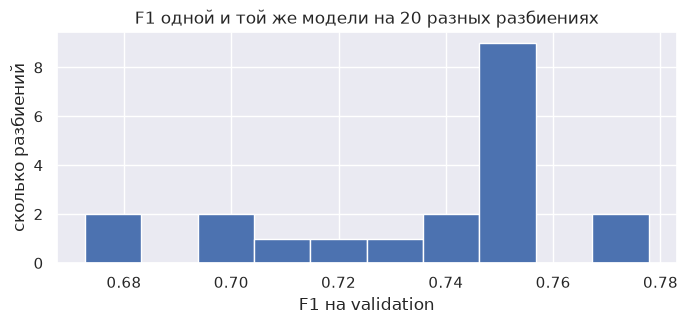

In [ ]:
single_split_scores = []
for seed in range(20):
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train, y_train, test_size=0.2, random_state=seed, stratify=y_train
    )
    model = make_rf().fit(X_tr, y_tr)
    single_split_scores.append(f1_score(y_val, model.predict(X_val)))

single_split_scores = np.array(single_split_scores)
print("F1 на одном разбиении (20 вариантов разбиения):")
print("  среднее = %.3f, std = %.3f" % (single_split_scores.mean(), single_split_scores.std()))
print("  min = %.3f, max = %.3f, размах = %.3f" % (single_split_scores.min(), single_split_scores.max(),
                                                   single_split_scores.max() - single_split_scores.min()))

plt.figure(figsize=(8, 3))
plt.hist(single_split_scores, bins=10)
plt.title("F1 одной и той же модели на 20 разных разбиениях")
plt.xlabel("F1 на validation")
plt.ylabel("сколько разбиений")
plt.show()

кросс валидация нужна чтобы оценить, как модель работает на новых данных, используя только train . По сравнению с одним разбиением кросс-валидация:
- использует все объекты train и для обучения, и для проверки ;
- усредняет оценку по `k` разным validation-выборкам, поэтому она гораздо меньше зависит от случайности разбиения;
- даёт не одно число, а `k` чисел — по ним видно разброс, то есть устойчивость модели;
- вместе с Pipeline защищает от утечки

Поэтому гиперпараметры выбираем по среднему F1 на кросс-валидации.

если многократно выбирать гиперпараметры по результату на test, test фактически станет частью обучения: гиперпараметры подстроятся под конкретные 179 пассажиров
test-выборки. Каждая оценка на test шумная (один пассажир — это примерно 0.01 F1), и если перебрать много вариантов
и взять лучший, мы выберем вариант, которому просто повезло с этими 179 людьми. В результате:
- финальное число на test окажется завышенным — это уже не честная оценка качества на новых данных;
- на действительно новых данных модель покажет результат хуже;
- данных для честной проверки не останется — test уже использован.


## 3. Baseline: Random Forest с параметрами по умолчанию

Baseline этой лабы - та же модель до оптимизации: `RandomForestClassifier` с параметрами по умолчанию.

In [ ]:
baseline = make_rf()

baseline_params = baseline.named_steps["model"].get_params()
for name in ["n_estimators", "max_depth", "min_samples_leaf", "max_features", "criterion", "bootstrap"]:
    print("%-17s = %s" % (name, baseline_params[name]))

n_estimators      = 100
max_depth         = None
min_samples_leaf  = 1
max_features      = sqrt
criterion         = gini
bootstrap         = True


In [10]:
baseline_cv = run_cv(baseline)

print_cv("Baseline", baseline_cv["test_score"])
# train_score — F1 на тех частях train, на которых модель обучалась
print("Train F1 = %.3f" % baseline_cv["train_score"].mean())
print("Разрыв train − CV = %.3f" % (baseline_cv["train_score"].mean() - baseline_cv["test_score"].mean()))

Baseline: CV F1 = 0.733 ± 0.014
  по фолдам: [0.745 0.716 0.736 0.75  0.718]
Train F1 = 0.979
Разрыв train − CV = 0.246


baseline получает CV F1 = 0.733 ± 0.014*, а на train — 0.979. Разрыв 0.25 - сильное переобучение:
деревья без ограничения глубины с листьями по одному объекту почти запоминают обучающую выборку.
Разброс по фолдам небольшой (0.716–0.750): модель стабильно хуже, чем могла бы быть.

## 4. Гиперпараметры

Беру 3 гиперпараметра, которые напрямую управляют сложностью отдельных деревьев и их разнообразием.
max_depth - глубина
min_samples_leaf - мин кол-во объектов в листе
max_features - сколько рандомных признаков в 1 разбиении

Сначала - сколько признаков получает модель после предобработки (от этого зависит диапазон `max_features`):

In [ ]:
prep_only = build_pipeline(None).named_steps["prep"]
n_features_after_prep = prep_only.fit_transform(X_train).shape[1]

print("Признаков после предобработки:", n_features_after_prep)
print('max_features="sqrt" ->', int(np.sqrt(n_features_after_prep)), "признака в каждом разбиении")
print("max_features=0.5    ->", int(0.5 * n_features_after_prep), "признаков")
print("max_features=None   ->", n_features_after_prep, "(все)")

Признаков после предобработки: 13
max_features="sqrt" -> 3 признака в каждом разбиении
max_features=0.5    -> 6 признаков
max_features=None   -> 13 (все)


## 5. Grid Search

Сетка - по 3–6 значений на параметр. До запуска считаю бюджет: число комбинаций × число фолдов = число обучений модели.

In [12]:
param_grid = {
    "model__max_depth": [3, 4, 5, 6, 8, None],
    "model__min_samples_leaf": [1, 2, 4, 8],
    "model__max_features": ["sqrt", 0.5, None],
}

n_grid_combinations = int(np.prod([len(values) for values in param_grid.values()]))
print("Комбинаций:", n_grid_combinations)
print("Обучений модели:", n_grid_combinations * N_SPLITS)

Комбинаций: 72
Обучений модели: 360


In [ ]:
grid_search = GridSearchCV(
    estimator=make_rf(n_estimators=N_ESTIMATORS),
    param_grid=param_grid,
    scoring=SCORING,
    cv=cv,
    n_jobs=N_JOBS,
    return_train_score=True,
)

start = time.perf_counter()
grid_search.fit(X_train, y_train)
grid_time = time.perf_counter() - start

grid_best_std = grid_search.cv_results_["std_test_score"][grid_search.best_index_]
print("Лучшие параметры:", grid_search.best_params_)
print("CV F1 = %.3f ± %.3f" % (grid_search.best_score_, grid_best_std))
print("Время поиска: %.1f с" % grid_time)

Лучшие параметры: {'model__max_depth': 8, 'model__max_features': None, 'model__min_samples_leaf': 2}
CV F1 = 0.777 ± 0.023
Время поиска: 9.1 с


In [ ]:
PARAM_NAMES = [name.replace("model__", "") for name in param_grid]


def results_table(search):
    # таблица всех проверенных комбинаций из cv_results_, отсортированная по качеству на CV
    raw = pd.DataFrame(search.cv_results_)
    table = pd.DataFrame()
    for name in PARAM_NAMES:
        table[name] = raw["param_model__" + name].apply(lambda v: str(round(v, 3)) if isinstance(v, float) else str(v))
    table["CV F1"] = raw["mean_test_score"]
    table["CV std"] = raw["std_test_score"]
    table["Train F1"] = raw["mean_train_score"]
    table["Разрыв train−CV"] = raw["mean_train_score"] - raw["mean_test_score"]
    table["fit, с"] = raw["mean_fit_time"]
    table["ранг"] = raw["rank_test_score"]
    return table.sort_values("ранг")


grid_raw = pd.DataFrame(grid_search.cv_results_)
grid_results = results_table(grid_search)
grid_results.head(10).round(3)

,max_depth,min_samples_leaf,max_features,CV F1,CV std,Train F1,Разрыв train−CV,"fit, с",ранг
57,8,2,None,0.777,0.023,0.889,0.113,0.363,1
56,8,1,None,0.777,0.018,0.927,0.150,0.375,2
69,None,2,None,0.773,0.022,0.913,0.140,0.359,3
7,3,8,0.5,0.771,0.044,0.774,0.003,0.311,4
70,None,4,None,0.771,0.026,0.864,0.093,0.333,5
13,4,2,sqrt,0.770,0.045,0.779,0.008,0.304,6
12,4,1,sqrt,0.770,0.045,0.779,0.009,0.309,6
14,4,4,sqrt,0.770,0.050,0.777,0.008,0.291,8
58,8,4,None,0.769,0.026,0.863,0.094,0.350,9
25,5,2,sqrt,0.768,0.047,0.796,0.028,0.308,10


In [ ]:
for delta in [0.005, 0.01, 0.02]:
    n_close = (grid_results["CV F1"] >= grid_search.best_score_ - delta).sum()
    print("В пределах %.3f от лучшей: %d комбинаций из %d" % (delta, n_close, n_grid_combinations))

print()
for name, values in param_grid.items():
    best_value = grid_search.best_params_[name]
    on_edge = best_value in (values[0], values[-1])
    print("%-25s лучшее = %-5s | на краю сетки: %s" % (name, best_value, on_edge))

print()
print("Худшая комбинация: CV F1 = %.3f" % grid_results["CV F1"].min())

В пределах 0.005 от лучшей: 3 комбинаций из 72
В пределах 0.010 от лучшей: 13 комбинаций из 72
В пределах 0.020 от лучшей: 31 комбинаций из 72

model__max_depth          лучшее = 8     | на краю сетки: False
model__min_samples_leaf   лучшее = 2     | на краю сетки: False
model__max_features       лучшее = None  | на краю сетки: True

Худшая комбинация: CV F1 = 0.734


Heatmap: CV F1 для каждой пары (`max_depth`, `min_samples_leaf`), отдельная картинка для каждого `max_features`.

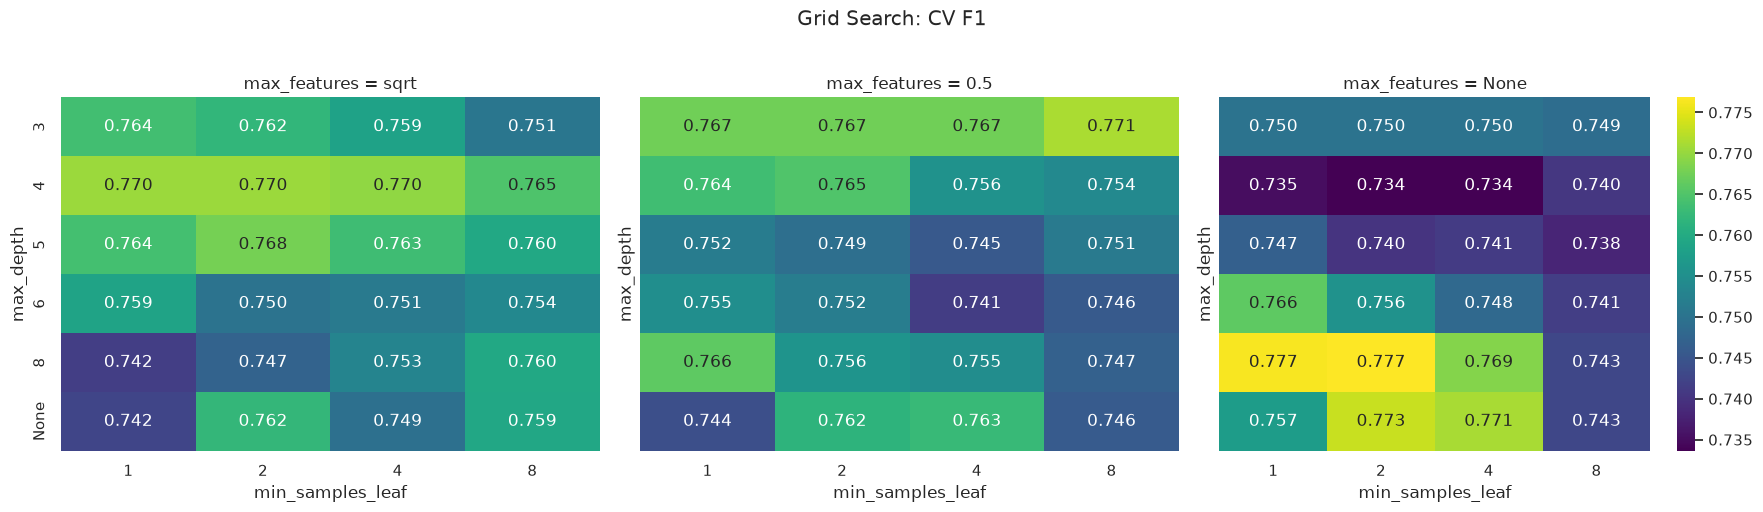

In [16]:
heat = grid_raw.copy()
heat["max_depth"] = heat["param_model__max_depth"].apply(str)
heat["min_samples_leaf"] = heat["param_model__min_samples_leaf"].astype(int)
heat["max_features"] = heat["param_model__max_features"].apply(str)
depth_order = [str(d) for d in param_grid["model__max_depth"]]

vmin, vmax = heat["mean_test_score"].min(), heat["mean_test_score"].max()  # общая шкала цвета
fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, mf in zip(axs, param_grid["model__max_features"]):
    part = heat[heat["max_features"] == str(mf)]
    pivot = part.pivot_table(index="max_depth", columns="min_samples_leaf", values="mean_test_score")
    pivot = pivot.loc[depth_order]  # строки в порядке сетки
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis", vmin=vmin, vmax=vmax, ax=ax, cbar=(ax is axs[-1]))
    ax.set_title("max_features = %s" % mf)
plt.suptitle("Grid Search: CV F1", y=1.02)
plt.tight_layout()
plt.show()

**Итоги Grid Search:**
1. `max_depth` ∈ {3, 4, 5, 6, 8, None}, `min_samples_leaf` ∈ {1, 2, 4, 8}, `max_features` ∈ {"sqrt", 0.5, None}, 200 деревьев;
2. комбинаций: 72, обучений: 72 × 5 = 360;
3. лучшие параметры: `max_depth=8`, `min_samples_leaf=2`, `max_features=None`;
4. CV F1 лучшей комбинации: 0.777 (baseline: 0.733);

- 13 комбинаций лежат в пределах 0.01 от лучшей, весь разброс сетки - от 0.734 до 0.777.
  Первые 3 места (0.777, 0.777, 0.773) отличаются меньше, чем std по фолдам.
- `max_depth=8` и `min_samples_leaf=2` — внутри диапазона. `max_features=None` на краю, но это и есть
  максимум (все 13 признаков), расширять некуда.
- при `max_features="sqrt"` лучшая глубина 4 (0.770), а глубокие деревья хуже
  (0.742); при `max_features=None` — наоборот, лучшая глубина 8 (0.777), а глубина 4 — одна из худших комбинаций (0.734).
- `min_samples_leaf` важен только для глубоких деревьев. При глубине 3–4 строки heatmap почти одинаковые, а при глубине 8/None со всеми признаками `min_samples_leaf=8`
  снижает CV с 0.777 до 0.743.
- В топ-10 две группы решений: глубокие деревья со всеми признаками (разрыв train−CV 0.09–0.15, std ~0.02)
  и неглубокие деревья (глубина 3–5) со случайной частью признаков (разрыв < 0.03, но std 0.044–0.05).

## 6. Random Search

те же три параметра и те же границы, что в сетке, только вместо фиксированных точек
используются распределения:
- `max_depth` — любое целое от 3 до 12 или `None`;
- `min_samples_leaf` — `randint(1, 9)`, то есть целое от 1 до 8;
- `max_features` — `uniform(0.2, 0.8)`, то есть доля признаков из отрезка [0.2, 1.0].

Бюджет: `n_iter` = числу комбинаций сетки (72), то есть столько же обучений, сколько у Grid Search.
Дополнительно — запуск с бюджетом втрое меньше (24 комбинации) и несколько разных `random_state` поиска:
насколько результат Random Search зависит от удачи.

In [ ]:
param_distributions = {
    "model__max_depth": list(range(3, 13)) + [None],
    "model__min_samples_leaf": randint(1, 9),
    "model__max_features": uniform(0.2, 0.8), 
}

N_ITER = n_grid_combinations
N_ITER_SMALL = N_ITER // 3 
print("N_ITER =", N_ITER, "| N_ITER_SMALL =", N_ITER_SMALL)

N_ITER = 72 | N_ITER_SMALL = 24


In [ ]:
def run_random_search(n_iter, seed=RANDOM_STATE):
    search = RandomizedSearchCV(
        estimator=make_rf(n_estimators=N_ESTIMATORS),
        param_distributions=param_distributions,
        n_iter=n_iter,
        scoring=SCORING,
        cv=cv,
        n_jobs=N_JOBS,
        random_state=seed,
        return_train_score=True,
    )
    start = time.perf_counter()
    search.fit(X_train, y_train)
    return search, time.perf_counter() - start


random_search, random_time = run_random_search(N_ITER)

random_best_std = random_search.cv_results_["std_test_score"][random_search.best_index_]
print("Лучшие параметры:", random_search.best_params_)
print("CV F1 = %.3f ± %.3f" % (random_search.best_score_, random_best_std))
print("Время поиска: %.1f с" % random_time)

Лучшие параметры: {'model__max_depth': 9, 'model__max_features': np.float64(0.9254627532366033), 'model__min_samples_leaf': 1}
CV F1 = 0.772 ± 0.019
Время поиска: 9.3 с


In [19]:
random_results = results_table(random_search)
random_results.head(10).round(3)

,max_depth,min_samples_leaf,max_features,CV F1,CV std,Train F1,Разрыв train−CV,"fit, с",ранг
54,9,1,0.925,0.772,0.019,0.941,0.169,0.371,1
55,11,1,0.718,0.771,0.012,0.965,0.193,0.356,2
61,10,1,0.762,0.771,0.016,0.954,0.183,0.350,3
33,3,2,0.685,0.770,0.043,0.777,0.007,0.303,4
36,4,7,0.276,0.769,0.047,0.776,0.006,0.295,5
25,11,5,0.969,0.768,0.031,0.853,0.084,0.353,6
67,3,6,0.707,0.767,0.043,0.775,0.008,0.314,7
70,9,3,0.809,0.767,0.026,0.876,0.109,0.319,8
63,9,1,0.598,0.767,0.028,0.930,0.163,0.332,9
45,3,8,0.451,0.766,0.043,0.773,0.006,0.299,10


In [ ]:
random_small, random_small_time = run_random_search(N_ITER_SMALL)

seed_rows = []
for seed in [0, 1, 2, 3, 4]:
    for n_iter in [N_ITER, N_ITER_SMALL]:
        search, _ = run_random_search(n_iter, seed=seed)
        seed_rows.append({"random_state": seed, "n_iter": n_iter, "лучший CV F1": search.best_score_})

seeds_table = pd.DataFrame(seed_rows).pivot(index="random_state", columns="n_iter", values="лучший CV F1")
seeds_table.columns = ["n_iter = %d" % c for c in seeds_table.columns]
print("Лучший CV F1 Random Search при разных random_state:")
print(seeds_table.round(3))
print()
print("Grid Search: %.3f" % grid_search.best_score_)

Лучший CV F1 Random Search при разных random_state:
              n_iter = 24  n_iter = 72
random_state                          
0                   0.771        0.780
1                   0.780        0.780
2                   0.770        0.773
3                   0.768        0.773
4                   0.766        0.772

Grid Search: 0.777


### Сравнение Grid Search и Random Search

В таблицу добавляю, сколько разных значений каждого параметра реально проверил поиск. Для `max_features`
считаю число признаков в разбиении, потому что разные доли могут давать одно и то же число признаков.

In [21]:
def n_unique_values(search):
    # сколько разных значений каждого параметра было проверено
    params = pd.DataFrame(search.cv_results_["params"])
    n_feat = params["model__max_features"].apply(
        lambda v: n_features_after_prep if v is None
        else int(np.sqrt(n_features_after_prep)) if v == "sqrt"
        else max(1, int(v * n_features_after_prep))
    )
    return params["model__max_depth"].apply(str).nunique(), params["model__min_samples_leaf"].nunique(), n_feat.nunique()


def comparison_row(name, search, elapsed):
    n_comb = len(search.cv_results_["params"])
    depth_u, leaf_u, feat_u = n_unique_values(search)
    return {
        "Метод": name,
        "Комбинаций": n_comb,
        "Обучений": n_comb * N_SPLITS,
        "CV F1": search.best_score_,
        "CV std": search.cv_results_["std_test_score"][search.best_index_],
        "Время, с": elapsed,
        "разных max_depth": depth_u,
        "разных min_samples_leaf": leaf_u,
        "разных чисел признаков": feat_u,
    }


comparison = pd.DataFrame([
    comparison_row("Grid Search", grid_search, grid_time),
    comparison_row("Random Search (n_iter=%d)" % N_ITER, random_search, random_time),
    comparison_row("Random Search (n_iter=%d)" % N_ITER_SMALL, random_small, random_small_time),
])
comparison.round(3)

,Метод,Комбинаций,Обучений,CV F1,CV std,"Время, с",разных max_depth,разных min_samples_leaf,разных чисел признаков
0,Grid Search,72,360,0.777,0.023,9.101,6,4,3
1,Random Search (n_iter=72),72,360,0.772,0.019,9.268,11,8,11
2,Random Search (n_iter=24),24,120,0.765,0.038,3.235,10,7,10


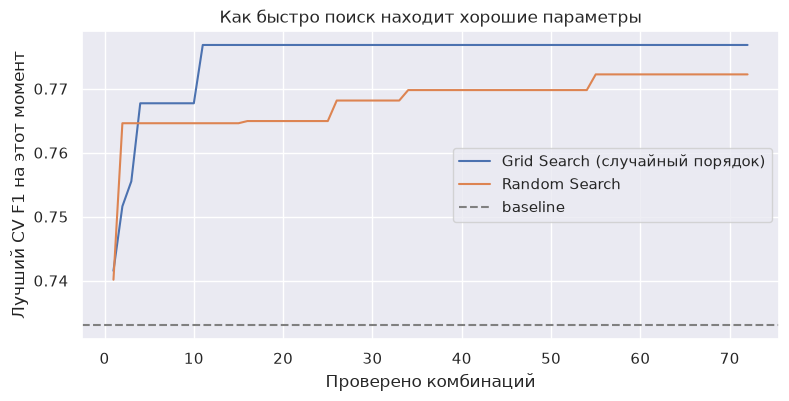

In [ ]:
rng = np.random.default_rng(RANDOM_STATE)
grid_scores = grid_search.cv_results_["mean_test_score"][rng.permutation(n_grid_combinations)]
random_scores = random_search.cv_results_["mean_test_score"]

plt.figure(figsize=(9, 4))
plt.plot(np.arange(1, len(grid_scores) + 1), np.maximum.accumulate(grid_scores), label="Grid Search (случайный порядок)")
plt.plot(np.arange(1, len(random_scores) + 1), np.maximum.accumulate(random_scores), label="Random Search")
plt.axhline(baseline_cv["test_score"].mean(), color="gray", linestyle="--", label="baseline")
plt.xlabel("Проверено комбинаций")
plt.ylabel("Лучший CV F1 на этот момент")
plt.title("Как быстро поиск находит хорошие параметры")
plt.legend()
plt.show()


- По качеству: Grid — 0.777, Random (72 итерации) - 0.772, Random (24 итерации) - 0.765.
- По числу комбинаций: при одинаковом бюджете Random проверил гораздо больше разных
  значений каждого параметра: 11 разных `max_depth` против 6, 8 значений `min_samples_leaf` против 4, 11 разных чисел
  признаков против 3. Сетка многократно повторяет одни и те же значения каждого параметра, меняя остальные.
- По времени: при равном числе обучений время почти одинаковое: время определяется числом обучений, а не
  способом выбора точек. 
- По кривой «лучший CV F1 к числу проверенных комбинаций»: обе кривые с первой же комбинации выше baseline.
  Random уже на 2-й комбинации нашёл 0.765, а дальше за 70 итераций добавил всего 0.007. Grid
  нашёл свой максимум 0.777 на 11-й комбинации.

Grid Search удобен, когда параметров мало, значения дискретные и нужно гарантированно проверить каждую комбинацию
(как здесь: 72 комбинации считаются за секунды).

## 7. Влияние гиперпараметров (validation curves)

Меняю один гиперпараметр, остальные фиксирую, и для каждого значения считаю средний F1 на train-частях фолдов
и на validation-фолдах. 
Остальные параметры:
- для `max_depth` — два варианта: при параметрах по умолчанию 
  и при лучших параметрах Grid Search;
- для остальных — параметры по умолчанию, чтобы влияние каждого параметра было видно отдельно.

Число деревьев везде `N_ESTIMATORS`.
Цветом отмечены зоны (подписаны в легенде): красная — недообучение, зелёная — разумная сложность, синяя — переобучение.

In [ ]:
ZONE_COLORS = {"недообучение": "tab:red", "разумная сложность": "tab:green", "переобучение": "tab:blue"}


def plot_validation_curve(param_name, param_range, base_params=None, ax=None, zones=None, title=None):
    # F1 на train- и validation-фолдах в зависимости от одного гиперпараметра.
    
    if base_params is None:
        base_params = {}
    if ax is None:
        ax = plt.gca()
    pipe = make_rf(**base_params)

    train_scores, val_scores = validation_curve(
        pipe, X_train, y_train,
        param_name="model__" + param_name, param_range=param_range,
        cv=cv, scoring=SCORING, n_jobs=N_JOBS,
    )
    train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
    val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)

    x = np.arange(len(param_range))
    ax.plot(x, train_mean, "o-", label="train")
    ax.fill_between(x, train_mean - train_std, train_mean + train_std, alpha=0.2)
    ax.plot(x, val_mean, "o-", label="validation (CV)")
    ax.fill_between(x, val_mean - val_std, val_mean + val_std, alpha=0.2)

    best = int(np.argmax(val_mean))
    ax.axvline(best, color="black", linestyle=":", label="лучшее по CV: %s" % param_range[best])

    if zones:
        for first, last, zone in zones:
            left = param_range.index(first) - 0.5
            right = param_range.index(last) + 0.5
            ax.axvspan(left, right, color=ZONE_COLORS[zone], alpha=0.1, label=zone)

    ax.set_xticks(x)
    ax.set_xticklabels([str(v) for v in param_range])
    ax.set_xlabel(param_name)
    ax.set_ylabel("F1")
    ax.set_title(title or param_name)
    ax.legend(loc="best", fontsize=9)

    return pd.DataFrame({
        param_name: [str(v) for v in param_range],
        "train F1": train_mean,
        "CV F1": val_mean,
        "CV std": val_std,
        "разрыв": train_mean - val_mean,
    }).set_index(param_name)


grid_best = {name.replace("model__", ""): value for name, value in grid_search.best_params_.items()}
default_base = {"n_estimators": N_ESTIMATORS}

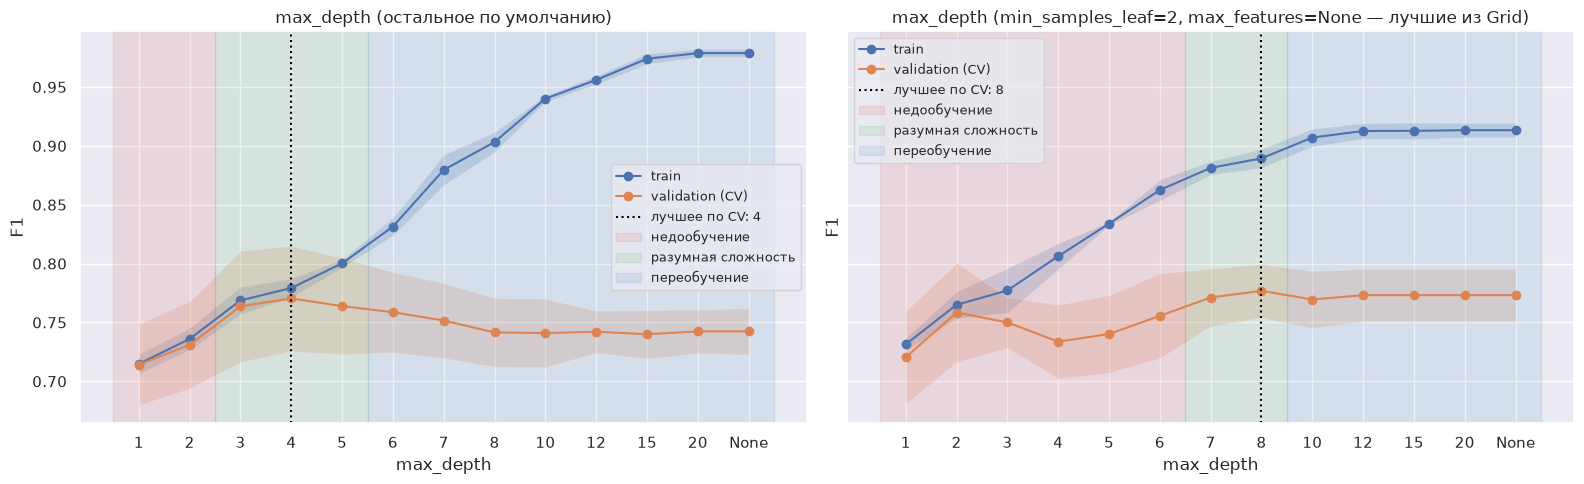

по умолчанию                      лучшие из Grid                \
              train F1  CV F1 CV std разрыв       train F1  CV F1 CV std   
max_depth                                                                  
1                0.715  0.714  0.035  0.001          0.731  0.720  0.040   
2                0.736  0.731  0.037  0.005          0.765  0.758  0.042   
3                0.769  0.764  0.047  0.005          0.777  0.750  0.022   
4                0.779  0.770  0.045  0.009          0.806  0.734  0.031   
5                0.800  0.764  0.041  0.036          0.834  0.740  0.033   
6                0.831  0.759  0.034  0.073          0.862  0.756  0.036   
7                0.880  0.752  0.032  0.128          0.881  0.771  0.024   
8                0.903  0.742  0.029  0.162          0.889  0.777  0.023   
10               0.940  0.741  0.029  0.199          0.907  0.769  0.024   
12               0.956  0.742  0.018  0.214          0.913  0.773  0.022   
15               0.974  0.740  0.021  0.234          0.913  0.773  0.022   
20               0.979  0.742  0.019  0.236          0.913  0.773  0.022   
None             0.979  0.742  0.020  0.236          0.913  0.773  0.022   

                  
          разрыв  
max_depth         
1          0.011  
2          0.007  
3          0.027  
4          0.073  
5          0.094  
6          0.107  
7          0.110  
8          0.113  
10         0.138  
12         0.139  
15         0.140  
20         0.140  
None       0.140

In [24]:
depth_range = [1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 15, 20, None]
best_base_no_depth = {**default_base, **{k: v for k, v in grid_best.items() if k != "max_depth"}}

fig, axs = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
depth_default = plot_validation_curve(
    "max_depth", depth_range, default_base, ax=axs[0],
    zones=[(1, 2, "недообучение"), (3, 5, "разумная сложность"), (6, None, "переобучение")],
    title="max_depth (остальное по умолчанию)")
depth_best = plot_validation_curve(
    "max_depth", depth_range, best_base_no_depth, ax=axs[1],
    zones=[(1, 6, "недообучение"), (7, 8, "разумная сложность"), (10, None, "переобучение")],
    title="max_depth (min_samples_leaf=%s, max_features=%s — лучшие из Grid)"
          % (grid_best["min_samples_leaf"], grid_best["max_features"]))
plt.tight_layout()
plt.show()

pd.concat({"по умолчанию": depth_default, "лучшие из Grid": depth_best}, axis=1).round(3)

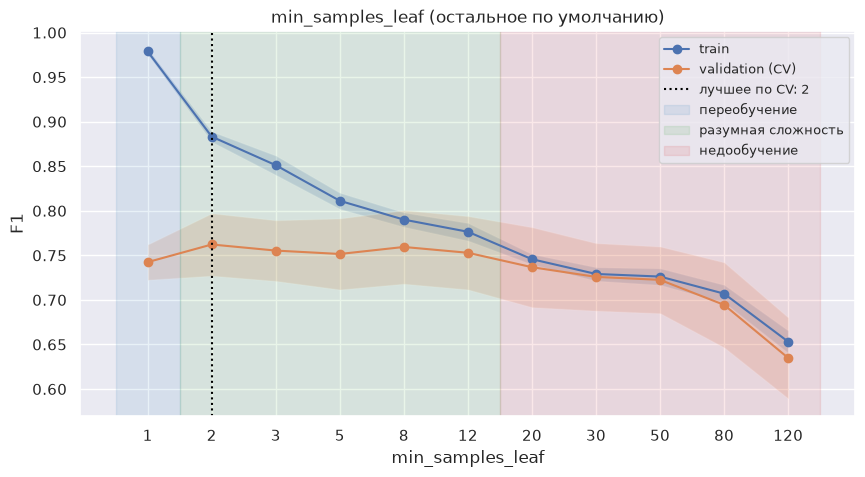

,train F1,CV F1,CV std,разрыв
min_samples_leaf,,,,
1,0.979,0.742,0.020,0.236
2,0.883,0.762,0.035,0.121
3,0.851,0.755,0.034,0.096
5,0.811,0.752,0.040,0.060
8,0.790,0.759,0.041,0.031
12,0.776,0.753,0.041,0.024
20,0.746,0.737,0.045,0.009
30,0.729,0.726,0.038,0.003
50,0.726,0.723,0.037,0.004


In [25]:
leaf_range = [1, 2, 3, 5, 8, 12, 20, 30, 50, 80, 120]

plt.figure(figsize=(10, 5))
leaf_curve = plot_validation_curve("min_samples_leaf", leaf_range, default_base, zones=[(1, 1, "переобучение"), (2, 12, "разумная сложность"), (20, 120, "недообучение")],
                                  
                                   title="min_samples_leaf (остальное по умолчанию)")
plt.show()
leaf_curve.round(3)

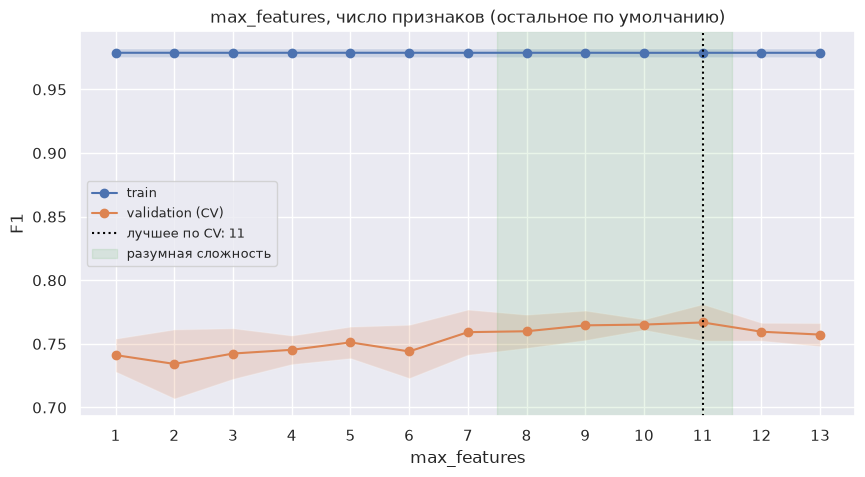

,train F1,CV F1,CV std,разрыв
max_features,,,,
1,0.979,0.741,0.013,0.238
2,0.979,0.734,0.027,0.245
3,0.979,0.742,0.020,0.236
4,0.979,0.745,0.011,0.233
5,0.979,0.751,0.012,0.228
6,0.979,0.744,0.021,0.235
7,0.979,0.759,0.018,0.220
8,0.979,0.760,0.013,0.219
9,0.979,0.765,0.012,0.214


In [26]:
feat_range = list(range(1, n_features_after_prep + 1))  # целое число = сколько признаков смотреть в разбиении

plt.figure(figsize=(10, 5))
feat_curve = plot_validation_curve("max_features", feat_range, default_base, zones=[(8, 11, "разумная сложность")],
                                  
                                   title="max_features, число признаков (остальное по умолчанию)")
plt.show()
feat_curve.round(3)

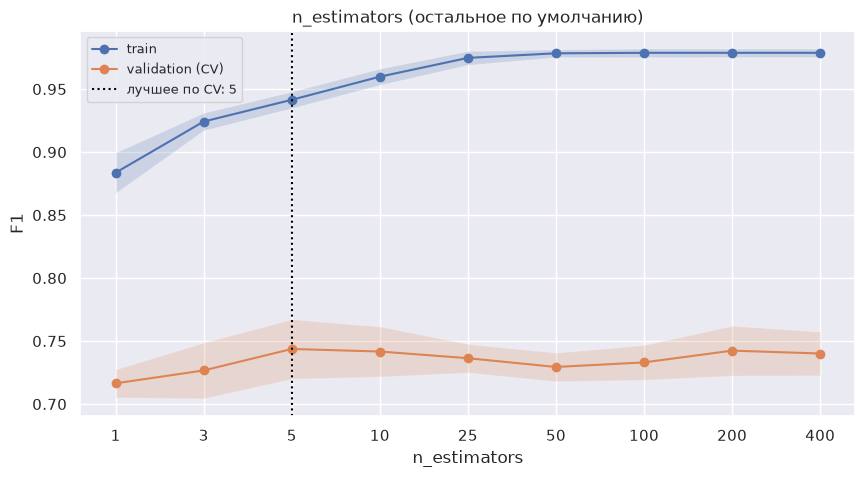

,train F1,CV F1,CV std,разрыв
n_estimators,,,,
1,0.884,0.716,0.011,0.167
3,0.924,0.727,0.022,0.198
5,0.942,0.744,0.024,0.198
10,0.960,0.742,0.020,0.218
25,0.975,0.736,0.011,0.238
50,0.978,0.729,0.011,0.249
100,0.979,0.733,0.014,0.246
200,0.979,0.742,0.020,0.236
400,0.979,0.740,0.017,0.239


In [27]:
trees_range = [1, 3, 5, 10, 25, 50, 100, 200, 400]

plt.figure(figsize=(10, 5))
trees_curve = plot_validation_curve("n_estimators", trees_range, {}, zones=None,
                                    title="n_estimators (остальное по умолчанию)")
plt.show()
trees_curve.round(3)

**`max_depth`, остальное по умолчанию**
- **недообучение - глубина 1–2:**
- **разумная сложность - глубина 3–5**, максимум при 4: CV F1 = 0.770, разрыв всего 0.01.
- переобучение — глубина 6 и больше

**`max_depth` при лучших параметрах Grid**
- максимум при глубине 8 (0.777), а на глубине 3–6 провал (0.734–0.756). Все деревья видят все 13 признаков,
  поэтому неглубокие деревья почти одинаковые и лес ведёт себя как одно неглубокое дерево. Более глубокие деревья
  успевают учесть взаимодействия (например, женщины 3-го класса + размер семьи) и сильнее отличаются друг от друга
  
- зона недообучения здесь — 1–6, разумная — 7–8, переобучение - 10 и глубже: разрыв train−CV
  растёт с 0.11 до 0.14, CV немного снижается (0.773).

**`min_samples_leaf`**
- ереобучение - 1: train 0.979, CV 0.742 — листья из одного пассажира запоминают шум;
- разумная сложность — 2–12: CV 0.752–0.762, разрыв train−CV быстро сокращается (с 0.12 до 0.02);
- недообучение — 20 и больше

**`max_features`**
- train F1 = 0.979 при любом значении: параметр не ограничивает глубину дерева, он меняет то, насколько деревья
  отличаются друг от друга. Поэтому классических зон недо-/переобучения здесь нет;
- 1–4 признака: CV 0.734–0.745 — дерево часто вынуждено делить по случайному слабому признаку (`Embarked`, `Title_Rare`),
  каждое дерево слабое;
- 8–11 признаков: CV 0.760–0.767 — лучший баланс между силой отдельного дерева и разнообразием;
- 12–13 признаков: CV немного ниже (0.757–0.760) — деревья становятся почти одинаковыми, усреднение помогает меньше.

**`n_estimators`:**
- CV растёт от 0.716 (1 дерево) до 0.74 уже к 5–10 деревьям, дальше — плато 0.73–0.74
- зоны переобучения нет

## 8. Финальная модель и проверка на test

Модели:
- **Baseline** — RF по умолчанию, обучен на всём train;
- **Grid Search** — `grid_search.best_estimator_` (уже переобучен на всём train);
- **Random Search** — `random_search.best_estimator_`;
- дополнительно **RF из ЛР2** (`max_depth=4`, 300 деревьев)

CV F1 для каждой модели — на одних и тех же 5 фолдах (baseline и RF из ЛР2 — через `run_cv`, поиски — из `cv_results_`).

In [28]:
baseline.fit(X_train, y_train)

lab2_rf = make_rf(n_estimators=300, max_depth=4)
lab2_rf_cv = run_cv(lab2_rf)
lab2_rf.fit(X_train, y_train)

final_models = {
    "Baseline (RF default)": baseline,
    "Grid Search": grid_search.best_estimator_,
    "Random Search": random_search.best_estimator_,
    "RF из ЛР2 (depth=4)": lab2_rf,
}

cv_fold_scores = {
    "Baseline (RF default)": baseline_cv["test_score"],
    "Grid Search": best_fold_scores(grid_search),
    "Random Search": best_fold_scores(random_search),
    "RF из ЛР2 (depth=4)": lab2_rf_cv["test_score"],
}

In [29]:
rows = []
test_predictions = {}
for name, model in final_models.items():
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)
    test_predictions[name] = y_pred_test
    rows.append({
        "Модель": name,
        "CV F1": cv_fold_scores[name].mean(),
        "CV std": cv_fold_scores[name].std(),
        "Train F1": f1_score(y_train, y_pred_train),
        "Test F1": f1_score(y_test, y_pred_test),
        "Test Accuracy": accuracy_score(y_test, y_pred_test),
        "Test Precision": precision_score(y_test, y_pred_test),
        "Test Recall": recall_score(y_test, y_pred_test),
    })

final_table = pd.DataFrame(rows).set_index("Модель")
final_table.round(3)

,CV F1,CV std,Train F1,Test F1,Test Accuracy,Test Precision,Test Recall
Модель,,,,,,,
Baseline (RF default),0.733,0.014,0.980,0.752,0.816,0.781,0.725
Grid Search,0.777,0.023,0.884,0.769,0.832,0.820,0.725
Random Search,0.772,0.019,0.930,0.779,0.838,0.823,0.739
RF из ЛР2 (depth=4),0.770,0.045,0.778,0.748,0.816,0.790,0.710


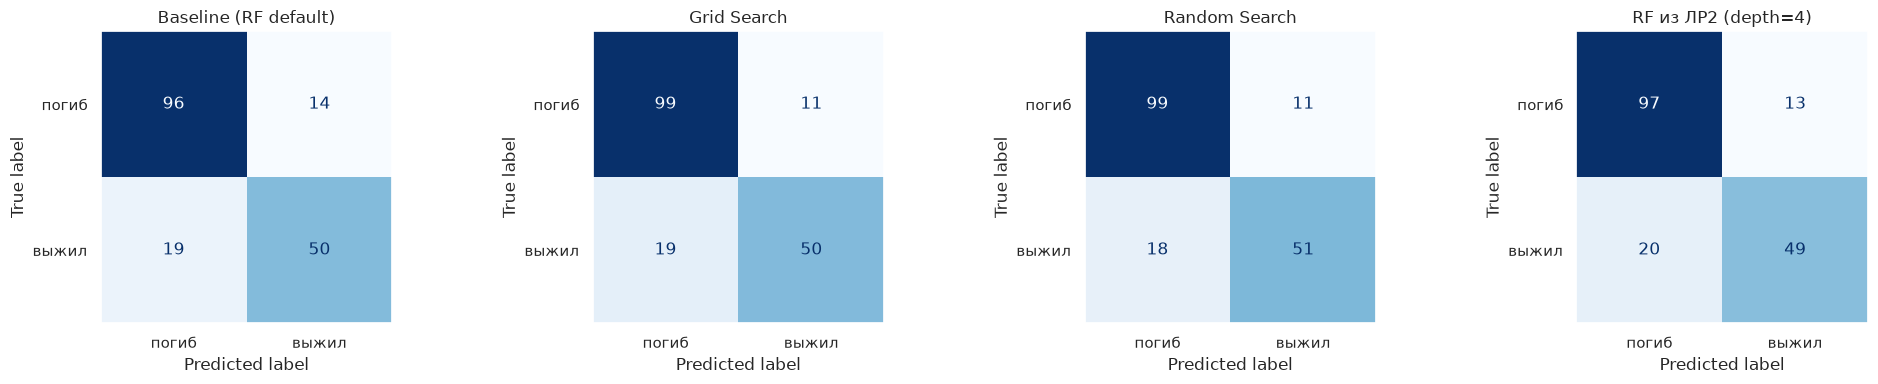

In [30]:
fig, axs = plt.subplots(1, len(test_predictions), figsize=(5 * len(test_predictions), 4))
for ax, (name, y_pred) in zip(axs, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=["погиб", "выжил"], cmap="Blues", colorbar=False, ax=ax
    )
    ax.set_title(name)
    ax.grid(False)
plt.tight_layout()
plt.show()

In [ ]:

y_pred = test_predictions["Grid Search"].copy()
fn_index = np.where((y_test.values == 1) & (y_pred == 0))[0][0]
y_pred_fixed = y_pred.copy()
y_pred_fixed[fn_index] = 1

print("Выживших в test:", y_test.sum(), "из", len(y_test))
print("Test F1 Grid-модели:            %.3f" % f1_score(y_test, y_pred))
print("Если угадать ещё 1 выжившего:   %.3f" % f1_score(y_test, y_pred_fixed))
print("Один пассажир = %.3f F1" % (f1_score(y_test, y_pred_fixed) - f1_score(y_test, y_pred)))

Выживших в test: 69 из 179
Test F1 Grid-модели:            0.769
Если угадать ещё 1 выжившего:   0.779
Один пассажир = 0.009 F1


**Насколько оптимизация улучшила качество**

- **CV:** 0.733 → **0.777** и 0.772 (Random, +0.039).
- **Test:** 0.752 → **0.769** (Grid, +0.017) и 0.779 (Random, +0.027).
- По confusion matrix: число найденных выживших почти не изменилось (TP 50 → 50 / 51), а ложных «выжил» стало меньше
- Переобучение уменьшилось: разрыв train−CV был 0.25 (0.979 vs 0.733), стал ~0.11 (0.884 vs 0.777).


обе оптимизированные модели лучше baseline и на CV, и на test. По величине — нет:
на test прирост меньше (+0.017 у Grid против +0.044 на CV). Кроме того, порядок Grid и Random на test обратный
(на CV лучше Grid, на test — Random), а RF из ЛР2 при CV 0.770 на test даёт 0.748 — на уровне baseline.


Финальной моделью остаётся **Grid Search** (`max_depth=8`, `min_samples_leaf=2`, `max_features=None`), так как выбор
делался по CV. Переключиться на Random из-за того, что на test у него на 0.010 больше, было бы выбором на тесте.

## 9. Анализ устойчивости

Все модели оценивались на одних и тех же фолдах (один объект `cv`)

In [32]:
folds = pd.DataFrame(cv_fold_scores).T
folds.columns = ["fold %d" % (i + 1) for i in range(N_SPLITS)]
fold_values = folds.values
folds["mean"] = fold_values.mean(axis=1)
folds["std"] = fold_values.std(axis=1)
folds["min"] = fold_values.min(axis=1)
folds["max"] = fold_values.max(axis=1)
folds["размах"] = folds["max"] - folds["min"]
folds.round(3)

,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std,min,max,размах
Baseline (RF default),0.745,0.716,0.736,0.750,0.718,0.733,0.014,0.716,0.750,0.034
Grid Search,0.782,0.745,0.812,0.785,0.760,0.777,0.023,0.745,0.812,0.066
Random Search,0.789,0.745,0.796,0.771,0.760,0.772,0.019,0.745,0.796,0.051
RF из ЛР2 (depth=4),0.789,0.725,0.849,0.736,0.752,0.770,0.045,0.725,0.849,0.124


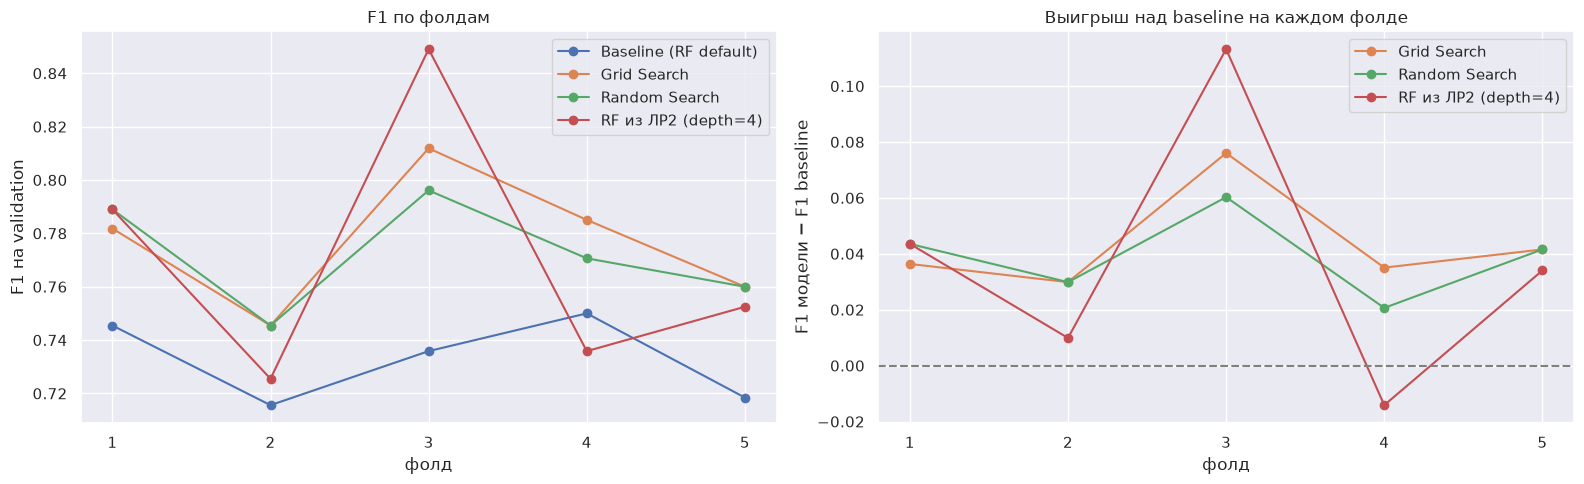

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(16, 5))
model_colors = dict(zip(cv_fold_scores, sns.color_palette()))

# F1 по фолдам
for name, scores in cv_fold_scores.items():
    axs[0].plot(np.arange(1, N_SPLITS + 1), scores, "o-", label=name, color=model_colors[name])
axs[0].set_xticks(np.arange(1, N_SPLITS + 1))
axs[0].set_xlabel("фолд")
axs[0].set_ylabel("F1 на validation")
axs[0].set_title("F1 по фолдам")
axs[0].legend()

for name in ["Grid Search", "Random Search", "RF из ЛР2 (depth=4)"]:
    diff = cv_fold_scores[name] - cv_fold_scores["Baseline (RF default)"]
    axs[1].plot(np.arange(1, N_SPLITS + 1), diff, "o-", label=name, color=model_colors[name])
axs[1].axhline(0, color="gray", linestyle="--")
axs[1].set_xticks(np.arange(1, N_SPLITS + 1))
axs[1].set_xlabel("фолд")
axs[1].set_ylabel("F1 модели − F1 baseline")
axs[1].set_title("Выигрыш над baseline на каждом фолде")
axs[1].legend()
plt.tight_layout()
plt.show()

### Одинаковое среднее — разная устойчивость

Ищу в результатах Grid Search две комбинации с почти одинаковым средним CV F1 (разница меньше 0.003),
но с максимально разным `std` по фолдам.

In [34]:
split_cols = ["split%d_test_score" % i for i in range(N_SPLITS)]
means = grid_raw["mean_test_score"].values
stds = grid_raw["std_test_score"].values

best_pair, best_gap = None, -1
for i in range(len(grid_raw)):
    for j in range(i + 1, len(grid_raw)):
        if abs(means[i] - means[j]) < 0.003 and abs(stds[i] - stds[j]) > best_gap:
            best_pair, best_gap = (i, j), abs(stds[i] - stds[j])

pair = grid_raw.loc[list(best_pair), ["params", "mean_test_score", "std_test_score"] + split_cols]
pair = pair.sort_values("std_test_score")
pair.index = ["Модель A (стабильная)", "Модель B (нестабильная)"]
pair["params"] = pair["params"].apply(lambda p: {k.replace("model__", ""): v for k, v in p.items()})
pair.columns = ["params", "CV F1", "CV std"] + ["fold %d" % (i + 1) for i in range(N_SPLITS)]
pd.set_option("display.max_colwidth", 80)
pair.round(3)

,params,CV F1,CV std,fold 1,fold 2,fold 3,fold 4,fold 5
Модель A (стабильная),"{'max_depth': None, 'max_features': None, 'min_samples_leaf': 1}",0.757,0.009,0.764,0.745,0.757,0.771,0.750
Модель B (нестабильная),"{'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 8}",0.760,0.045,0.792,0.725,0.832,0.733,0.716


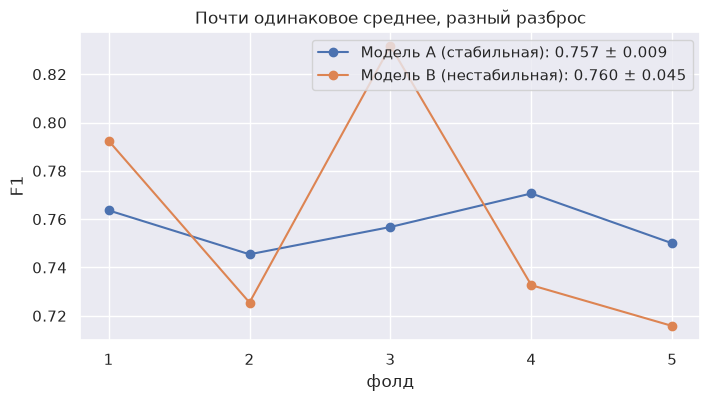

In [35]:
plt.figure(figsize=(8, 4))
for label, row in pair.iterrows():
    plt.plot(np.arange(1, N_SPLITS + 1), row[["fold %d" % (i + 1) for i in range(N_SPLITS)]].values.astype(float),
             "o-", label="%s: %.3f ± %.3f" % (label, row["CV F1"], row["CV std"]))
plt.xticks(np.arange(1, N_SPLITS + 1))
plt.xlabel("фолд")
plt.ylabel("F1")
plt.title("Почти одинаковое среднее, разный разброс")
plt.legend()
plt.show()

### Повторённая кросс-валидация

5 чисел — это мало, чтобы уверенно сказать, что улучшение больше шума. Повторяю 5-fold CV 10 раз с разными
разбиениями (`RepeatedStratifiedKFold`, 50 оценок на модель). Разбиения здесь **другие**, не те, на которых выбирались
параметры, поэтому это ещё и проверка, не подогнаны ли лучшие параметры под конкретные 5 фолдов. Test по-прежнему не используется.

In [36]:
repeated_cv = RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=10, random_state=RANDOM_STATE)

repeated_models = {
    "Baseline (RF default)": make_rf(),
    "Grid Search": make_rf(n_estimators=N_ESTIMATORS, **grid_best),
    "Random Search": make_rf(n_estimators=N_ESTIMATORS,
                             **{k.replace("model__", ""): v for k, v in random_search.best_params_.items()}),
    "RF из ЛР2 (depth=4)": make_rf(n_estimators=300, max_depth=4),
}

repeated_scores = {}
for name, model in repeated_models.items():
    repeated_scores[name] = cross_val_score(model, X_train, y_train, cv=repeated_cv, scoring=SCORING, n_jobs=N_JOBS)

rep_rows = []
for name, scores in repeated_scores.items():
    diff = scores - repeated_scores["Baseline (RF default)"]  # разбиения одинаковые -> разница попарная
    rep_rows.append({
        "Модель": name,
        "CV F1 (50 оценок)": scores.mean(),
        "std": scores.std(),
        "min": scores.min(),
        "max": scores.max(),
        "выигрыш над baseline": diff.mean(),
        "доля разбиений, где лучше baseline": (diff > 0).mean(),
    })
pd.DataFrame(rep_rows).set_index("Модель").round(3)

,CV F1 (50 оценок),std,min,max,выигрыш над baseline,"доля разбиений, где лучше baseline"
Модель,,,,,,
Baseline (RF default),0.740,0.043,0.607,0.843,0.000,0.00
Grid Search,0.767,0.043,0.654,0.857,0.027,0.88
Random Search,0.763,0.042,0.648,0.851,0.023,0.84
RF из ЛР2 (depth=4),0.767,0.044,0.667,0.863,0.026,0.72


**Ответ:**
- **Разброс по фолдам:** у baseline std 0.014 (0.716–0.750) — он самый стабильный, но стабильно хуже всех.
  У Grid 0.023 (0.745–0.812), у Random 0.019 (0.745–0.796). У RF из ЛР2 при почти том же среднем (0.770) разброс
  вдвое больше: std 0.045, размах 0.124 (от 0.725 до 0.849).
- **Улучшение есть на каждом фолде:** Grid лучше baseline на всех 5 фолдах (+0.029 … +0.076), Random тоже. RF из ЛР2
  на фолде 4 проигрывает baseline: его среднее в основном держится на очень удачном фолде 3 (0.849).
- **Пара «A vs B» из сетки:** A (`max_depth=None`, все признаки, `min_samples_leaf=1`) — 0.757 ± 0.009, фолды 0.745–0.771;
  B (`max_depth=8`, `"sqrt"`, `min_samples_leaf=8`) — 0.760 ± 0.045, фолды 0.716–0.832. Среднее одинаковое, но качество B
  сильно зависит от того, какие пассажиры попали в validation.
- **Повторённая CV (50 разбиений):** параметры Grid дают 0.767 (на исходных 5 фолдах было 0.777 — около 0.01
  оптимизма из-за выбора лучшего из 72) и лучше baseline в 88% разбиений; Random — в 84%; RF из ЛР2 при том же
  среднем 0.767 — только в 72%. Std одного фолда у всех моделей ≈ 0.043: на 50 разбиениях видно, что шум
  validation-фолда из 142 человек сам по себе большой, и std, посчитанный всего по 5 фолдам, — тоже грубая оценка.
  Поэтому выводы об устойчивости лучше проверять на повторённой CV.


При равном среднем лучше выбрать более устойчивую модель: её качество на новых данных предсказуемее, а оценка CV
надёжнее. Если разница в среднем меньше разброса по фолдам, её нельзя считать реальным преимуществом.

## 10. Выводы

1. **Задача и baseline.** Titanic, Random Forest, метрика F1 по классу «выжил». Baseline — RF с параметрами по умолчанию:
   CV F1 = 0.733 ± 0.014, test F1 = 0.752, сильное переобучение (train F1 0.979).
2. **Кросс-валидация.** `StratifiedKFold` на 5 фолдов, один и тот же объект `cv` для всех экспериментов. 5 фолдов — компромисс
   между шумом оценки на маленьком фолде (k = 10) и долей данных для обучения (k = 3). Одно разбиение train/validation
   даёт F1 от 0.67 до 0.78 для одной и той же модели — по нему подбирать параметры нельзя.
3. **Гиперпараметры.** `max_depth`, `min_samples_leaf`, `max_features`; `n_estimators` зафиксирован (200), потому что
   переобучения от числа деревьев нет — validation curve выходит на плато уже к ~10 деревьям.
   У `max_depth` и `min_samples_leaf` хорошо видны все три зоны: недообучение, разумная сложность, переобучение.
   `max_features` управляет не сложностью дерева, а разнообразием деревьев. Параметры сильно взаимодействуют:
   оптимальная глубина при 3 признаках — 4, а при всех признаках — 8.
4. **Grid vs Random.** Grid (72 комбинации, 360 обучений, ~9 с) — CV F1 0.777; Random с тем же бюджетом — 0.772
   (0.772–0.780 при разных `random_state`), с бюджетом втрое меньше — 0.765. Разницы меньше разброса по фолдам — методы
   эквивалентны по качеству, но Random проверяет гораздо больше разных значений каждого параметра и лучше подходит
   для больших пространств.
5. **Test.** Baseline 0.752 → Grid 0.769 → Random 0.779. Улучшение на test меньше, чем на CV (+0.017 против +0.044),
   из-за маленького test (1 пассажир ≈ 0.009 F1) и оптимистичности `best_score_` (на новых разбиениях лучшие параметры дают 0.767).
   Финальная модель — Grid Search, потому что выбрана по CV.
6. **Устойчивость.** Оптимизированные модели лучше baseline на каждом из 5 фолдов и в 84–88% из 50 повторных разбиений.
   Модели с одинаковым средним могут сильно отличаться разбросом (0.757 ± 0.009 против 0.760 ± 0.045).
7. **Честность эксперимента.** `X_test` / `y_test` использовались только для разбиения (раздел 1) и для одной финальной
   проверки (раздел 8). Все решения о гиперпараметрах приняты по кросс-валидации на train.